# Eligiendo modelos con incertidumbre

> All models are wrong, but some are useful.

George Box

> If you torture the data long enough, it will confess.

Ronald Coase

Necesitamos ganar la competencia. Para lograr esto, necesitamos "construir" el mejor modelo posible. Lo que nos platea dos preguntas clave:
* ¿qué significa construir un modelo?
* Y, en segundo lugar, si tenemos dos modelos, ¿cómo determinamos cuál es el mejor?

Empecemos realizando una comparación entre el modelo por defecto  de **árboles de decisión** (no controla el crecimiento) y uno levemente parametrizado.

Levantemos el entorno e instalemos los paquetes que nos probablemente no dispongamos. Se usarán a lo largo de la clase.

In [ ]:
%pip install optuna

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree,  _tree
from sklearn.model_selection import train_test_split
from sklearn.model_selection import ShuffleSplit, StratifiedShuffleSplit

from joblib import Parallel, delayed

from time import time

import optuna
from optuna.visualization import plot_param_importances, plot_contour,  plot_slice, plot_optimization_history

c:\Users\keila\OneDrive\Desktop\py\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Notará a continuación que trabajaremos como mes de entrenamiento **Marzo** y reservaremos **Mayo** solo para pruebas

In [3]:
dataset_path = '../'
dataset_file = 'competencia_01.csv'

ganancia_acierto = 1_072_500
costo_estimulo = 27_500

mes_train = 202103
mes_test = 202105

# agregue su semilla
semilla = 17

data = pd.read_csv(dataset_path + dataset_file)

In [4]:
X = data[data['foto_mes'] == mes_train]
y = X['clase_ternaria']
X = X.drop(columns=['clase_ternaria'])

Y necesitamos una función que nos ayude a calcular la ganancia.

El parámetro `prop`, esta para corregir la ganancia cuando no estemos trabajando con una población entera. Si estamos utilizando, por ejemplo una muestra del 70%, para normalizar la ganancia, ponermos el parámetro `prop=0.7`



In [5]:
def ganancia(model, X, y, prop=1, threshold=0.025):

  class_index = np.where(model.classes_ == "BAJA+2")[0][0]
  y_hat = model.predict_proba(X)

  @np.vectorize
  def ganancia_row(predicted, actual, threshold=0.025):
    return  (predicted >= threshold) * (ganancia_acierto if actual == "BAJA+2" else -costo_estimulo)

  return ganancia_row(y_hat[:,class_index], y).sum() / prop

Mira a continuación el siguiente código.

* ¿Cuál cree que es el mejor modelo?
* ¿Cuáles son los problemas que ve?

In [6]:
model_base = DecisionTreeClassifier()
model_ale = DecisionTreeClassifier(criterion='gini',
                               min_samples_split=80,
                               max_depth=5)

model_base.fit(X,y)
model_ale.fit(X,y)

print(f"Ganancia de modelo Base: {ganancia(model_base, X, y):,.0f}")
print(f"Ganancia de modelo Ale:  {ganancia(model_ale, X, y):,.0f}")

Ganancia de modelo Base: 1,022,092,500
Ganancia de modelo Ale:  292,985,000


* ¿Cómo se pueden solucionar?

Dado que lo que hicimos no pinta nada bien, pasemos a una de las herramientas que separa la ciencia de datos de la estadística tradicional

* ¿Por qué separamos en train/test?
* ¿Cómo funciona la estadística tradicional?
* ¿Son números aleatorios los que nos dan las computadoras?
* ¿Por qué usamos semillas?
* ¿Qué es una partición estratificada?
* ¿Es realmente necesario en nuestro caso una partición estratificada?



Veamos alguna de las formas de separar los conjuntos de datos para medir su calidad:

* **Train-Test Split**: Divide el conjunto de datos en dos partes: un conjunto de entrenamiento y otro de prueba. El conjunto de entrenamiento se utiliza para ajustar el modelo, y el conjunto de prueba para evaluar su rendimiento.

* **K-Fold Cross Validation**: Divide los datos en k subconjuntos o folds. El modelo se entrena k veces, cada vez utilizando k-1 subconjuntos como entrenamiento y el subconjunto restante como prueba. Esto se repite hasta que cada subconjunto se haya utilizado como conjunto de prueba una vez.

* **Shuffle Split** (aka Montecarlo Cross Validation): Genera múltiples particiones aleatorias de los datos en conjuntos de entrenamiento y prueba. A diferencia de K-Fold, no garantiza que todos los puntos de datos sean utilizados en alguna iteración.

En la cátedra preferimos usar está última, pero el alumno es libre de usar la que considera conveniente.

Armemos ahora nuevamente los modelos anteriores, pero utilizando estas particiones y midiendo ya no en **train**, sino en los múltiples conjunto de **test**

In [7]:
sss = StratifiedShuffleSplit(n_splits=20,
                             test_size=0.3,
                             random_state=semilla)

# Función que paraleliza la construcción de árboles de decisión
def train_and_evaluate(train_index, test_index, params, X, y):
  m = DecisionTreeClassifier(**params)
  m.fit(X.iloc[train_index],y.iloc[train_index])
  # Note que con el parámetro prop se corrige la distorsión por sampleo de la
  # ganancia
  ganancia_value = ganancia(m, X.iloc[test_index], y.iloc[test_index], prop=0.3)
  return m, ganancia_value

modelo_base_param = {"random_state":semilla}

modelo_ale_param = {"criterion": 'gini',
                     "random_state":semilla,
                     "min_samples_split":80,
                     "max_depth":5,
}

results_base = Parallel(n_jobs=-1)(
    delayed(train_and_evaluate)(train_index, test_index, modelo_base_param, X, y)
    for train_index, test_index in sss.split(X, y)
)

results_ale = Parallel(n_jobs=-1)(
    delayed(train_and_evaluate)(train_index, test_index, modelo_ale_param, X, y)
    for train_index, test_index in sss.split(X, y)
)


Estamos haciendo por cada juego de parámetros 20 modelos. Esto no suele ser lo habitual. Con 5 se puede conseguir resultados aceptables para una comparación inicial.

Vamos a ver que tan bien le fue a los modelos en los conjuntos de **test**:

In [8]:
ganancias_modelos_base = [result[1] for result in results_base]
ganancias_modelos_ale = [result[1] for result in results_ale]

df_pred = pd.DataFrame({'Ganancia': [result[1] for result in results_base], 'Modelo': 'Base'})
df_pred2 = pd.DataFrame({'Ganancia': [result[1] for result in results_ale], 'Modelo': 'Ale'})
df_combined = pd.concat([df_pred, df_pred2])
df_combined_pivot = df_combined.pivot(columns='Modelo', values='Ganancia')
display(df_combined_pivot)

Modelo,Ale,Base
0,2.286167e+08,4.345000e+07
1,2.618917e+08,4.033333e+07
2,2.026750e+08,5.151667e+07
3,2.177083e+08,4.161667e+07
4,2.563000e+08,2.328333e+07
5,2.114750e+08,2.860000e+07
6,2.678500e+08,4.161667e+07
7,2.329250e+08,2.979167e+07
8,2.815083e+08,3.905000e+07
9,2.553833e+08,5.500000e+07


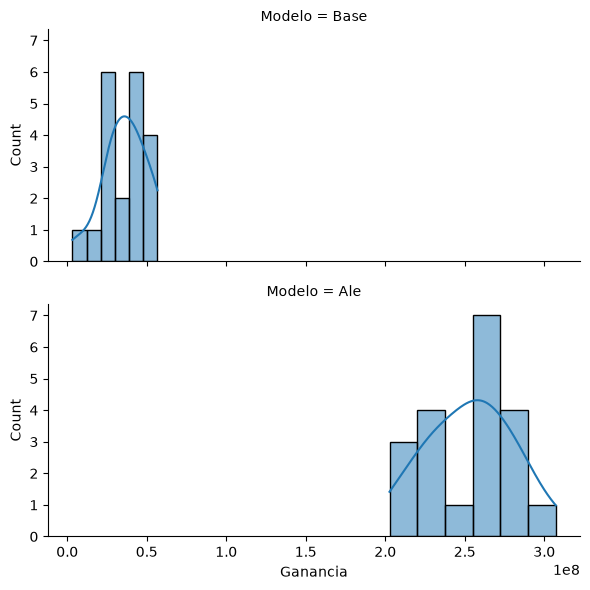

In [9]:
g = sns.FacetGrid(df_combined, row="Modelo", aspect=2)
g.map(sns.histplot, "Ganancia", kde=True)
plt.show()

* ¿Qué tan distintos son de los primero valores calculados con el modelo completo?
* ¿Con cuál se queda?
* ¿Por qué se produce semejante dispersión?
* ¿Cuál considera que es el "valor real"?

Podemos mirar la media

In [10]:
mean_base = df_combined[df_combined['Modelo'] == 'Base']['Ganancia'].mean()
mean_ale = df_combined[df_combined['Modelo'] == 'Ale']['Ganancia'].mean()

print(f"Ganancia media del modelo base:\t{mean_base/0.3:,.0f}")
print(f"Ganancia media del modelo ale:\t{mean_ale/0.3:,.0f}")

Ganancia media del modelo base:	120,450,000
Ganancia media del modelo ale:	843,180,556


* Si no le gusta la media, ¿cómo más puede elegir entre dos modelos?

Muy interesante, pero lo importante es que sucedería en el **futuro**. Por este motivo nos guardamos el mes de **Mayo**.

In [11]:
X_futuro = data[data['foto_mes'] == mes_test]
y_futuro = X_futuro['clase_ternaria']
X_futuro = X_futuro.drop(columns=['clase_ternaria'])

Sobre el mes de Mayo, **debemos usar el modelo que se entreno sobre todos los datos**

In [12]:
ganancia_mayo_base = ganancia(model_base, X_futuro, y_futuro)
ganancia_mayo_ale = ganancia(model_ale, X_futuro, y_futuro)

print(f"Ganancia de modelo Base en Abril:\t{ganancia_mayo_base:,.0f}")
print(f"Ganancia de modelo Ale en Abril:\t{ganancia_mayo_ale:,.0f}")


Ganancia de modelo Base en Abril:	-165,000
Ganancia de modelo Ale en Abril:	191,152,500


* ¿Cuál es mejor?
* ¿Por qué cree que el mejor es el mejor?
* ¿Hubiera elegido sabiamente únicamente con los datos de **Febrero**?

El mundo es un lugar **cruel** para los data scientists. El escenario anterior tampoco es el presente para los alumnos. Ya que la primera competencia sigue el modelo **kaggle** que divide el dataset en una parte **pública** y otra **privada**. Simulemos los efectos que produce en la decisión del mejor modelo en los leaderboards, simulando varios a la vez.


In [13]:
# podemos tomar más muestras, dado que solo vamos a scorear y eso es más rápido
sss_futuro = StratifiedShuffleSplit(n_splits=50,
                             test_size=0.3,
                             random_state=semilla)

ganancias_futuro_privada_ale = []
ganancias_futuro_privada_base = []
ganancias_futuro_publica_ale = []
ganancias_futuro_publica_base = []

for train_index, test_index in sss_futuro.split(X_futuro, y_futuro):
  ganancias_futuro_privada_ale.append(ganancia(model_ale, X_futuro.iloc[train_index], y_futuro.iloc[train_index], prop=0.7))
  ganancias_futuro_privada_base.append(ganancia(model_base, X_futuro.iloc[train_index], y_futuro.iloc[train_index], prop=0.7))
  ganancias_futuro_publica_ale.append(ganancia(model_ale, X_futuro.iloc[test_index], y_futuro.iloc[test_index], prop=0.3))
  ganancias_futuro_publica_base.append(ganancia(model_base, X_futuro.iloc[test_index], y_futuro.iloc[test_index], prop=0.3))


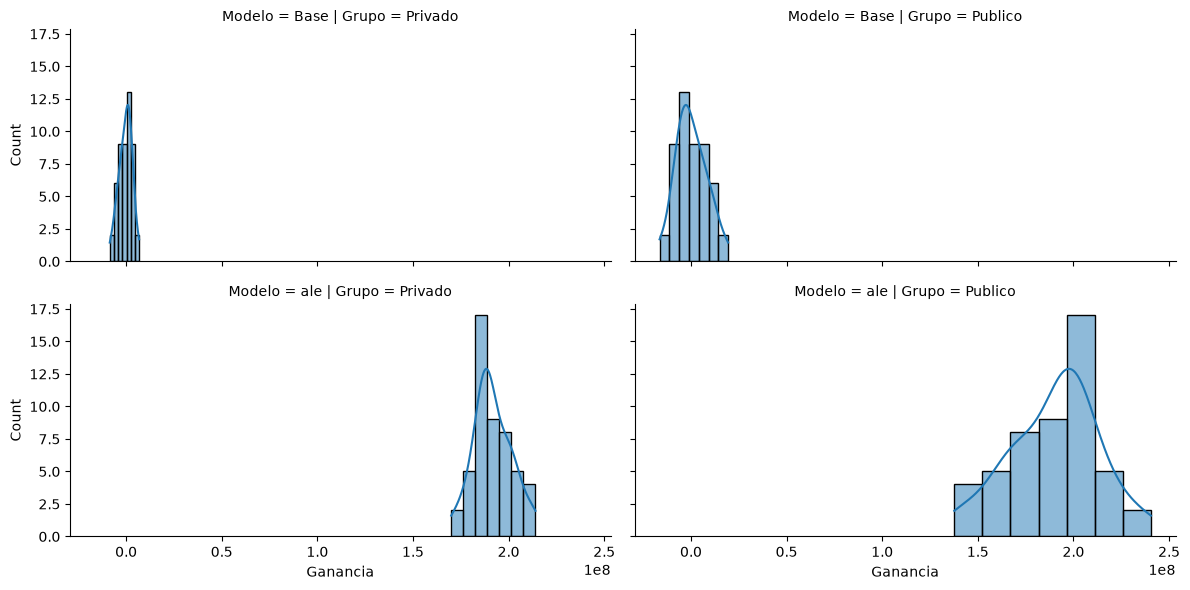

In [14]:
df_pred_1_ale = pd.DataFrame({'Ganancia': ganancias_futuro_privada_ale, 'Modelo': 'ale', 'Grupo': 'Privado'})
df_pred_2_ale = pd.DataFrame({'Ganancia': ganancias_futuro_publica_ale, 'Modelo': 'ale', 'Grupo': 'Publico'})
df_pred_1_base = pd.DataFrame({'Ganancia': ganancias_futuro_privada_base, 'Modelo': 'Base', 'Grupo': 'Privado'})
df_pred_2_base = pd.DataFrame({'Ganancia': ganancias_futuro_publica_base, 'Modelo': 'Base', 'Grupo': 'Publico'})

df_combined = pd.concat([df_pred_1_base, df_pred_2_base, df_pred_1_ale, df_pred_2_ale ])

g = sns.FacetGrid(df_combined, col="Grupo", row="Modelo", aspect=2)
g.map(sns.histplot, "Ganancia", kde=True)
plt.show()


In [15]:
mean_base_privado = df_combined[(df_combined['Modelo'] == 'Base') & (df_combined['Grupo'] == 'Privado')]['Ganancia'].mean()
mean_base_publico = df_combined[(df_combined['Modelo'] == 'Base') & (df_combined['Grupo'] == 'Publico')]['Ganancia'].mean()
mean_ale_privado = df_combined[(df_combined['Modelo'] == 'ale') & (df_combined['Grupo'] == 'Privado')]['Ganancia'].mean()
mean_ale_publico = df_combined[(df_combined['Modelo'] == 'ale') & (df_combined['Grupo'] == 'Publico')]['Ganancia'].mean()

print(f"Ganancia media del modelo base en privado: {mean_base_privado}")
print(f"Ganancia media del modelo base en publico: {mean_base_publico}")
print(f"Ganancia media del modelo ale en privado: {mean_ale_privado}")
print(f"Ganancia media del modelo ale en publico: {mean_ale_publico}")


Ganancia media del modelo base en privado: -348857.14285714284
Ganancia media del modelo base en publico: 264000.00000000006
Ganancia media del modelo ale en privado: 191619214.2857143
Ganancia media del modelo ale en publico: 190063500.00000003


* ¿Que significan estos resultados?

Dos cosas.

* El modelo ale, es un caso de **vagancia**. Cambiar 2 parámetros y esperar un cambio radical no es lo más inteligente que se puede hacer. Realmente hay que hacer un esfuerzo para separar las distribuciones.
* Elegir un modelo no es una tarea simple que se pueda hacer con una **certeza** absoluta.

Para encontrar buenos modelos una forma adecuada es la búsqueda de hiperparámetros. Podemos contar con las siguientes técnicas de búsqueda de hiperparámetros:

* **Grid Search**: Explora exhaustivamente todas las combinaciones posibles de hiperparámetros dentro de un conjunto predefinido de valores. Aunque es exhaustivo.

* **Random Search**: En lugar de probar todas las combinaciones posibles, selecciona un número aleatorio de combinaciones de hiperparámetros dentro de un rango predefinido.

* **Bayesian Optimization**: Este método construye un modelo probabilístico del rendimiento de los hiperparámetros y utiliza ese modelo para seleccionar los valores de hiperparámetros más prometedores.

* **Tree-structured Parzen Estimator (TPE)**: Una variante de la optimización bayesiana que utiliza estimadores de densidad basados en árboles (Parzen estimators) para modelar la probabilidad de los hiperparámetros óptimos. Es eficiente en la exploración de espacios de hiperparámetros complejos y se adapta bien a configuraciones con interdependencias entre los parámetros.

* **Genetic Algorithms**: Emplea principios de la evolución natural, como selección, cruce y mutación, para encontrar combinaciones óptimas de hiperparámetros. Es útil en espacios de búsqueda muy complejos, aunque puede ser computacionalmente costoso.

Todos son buenas opciones para la búsqueda de ... nah mentira, **grid search** apesta, si no me cree calcule el tiempo necesario para barrer el dominio de búsqueda.

Para la búsquedas de parámetros usaremos **Optuna**. **Optuna** es una librería poderosa y flexible, diseñada para realizar búsquedas eficientes y automatizadas.

* Utiliza casi todos los álgoritmos mencionados y más.

* Permite definir espacios de búsqueda complejos, incluyendo hiperparámetros categóricos, continuos, discretos y con dependencias condicionales.

* Ofrece un mecanismo de pruning o poda, que permite detener evaluaciones de configuraciones de hiperparámetros que no muestran promesas tempranas.

* Facilidad de Uso y Configuración.

* Proporciona herramientas de visualización integradas para analizar el progreso de la optimización, visualizar la importancia de los hiperparámetros y explorar las configuraciones probadas.

Buscaremos un mejor modelo de manera inteligente:

In [16]:

sss_opt = ShuffleSplit(n_splits=5, test_size=0.3, random_state=semilla)

def objective(trial, X, y, sss):
  # Limitaremos la busqueda a solo 3 hiperparámetros, pero puede poner los que quiera
  # criterion = trial.suggest_categorical('criterion', ['gini', 'entropy'])
  max_depth = trial.suggest_int('max_depth', 2, 20)
  min_samples_split = trial.suggest_int('min_samples_split', 2, 200)
  min_samples_leaf = trial.suggest_int('min_samples_leaf', 1, 20)
  # max_leaf_nodes = trial.suggest_int('max_leaf_nodes', 2, 20)

  def train_and_evaluate(train_index, test_index, X, y):
    m = DecisionTreeClassifier(
        # criterion=criterion,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        # max_leaf_nodes=max_leaf_nodes,
        random_state=semilla,
    )
    m.fit(X.iloc[train_index],y.iloc[train_index])
    ganancia_value = ganancia(m, X.iloc[test_index], y.iloc[test_index], prop=0.3)
    return ganancia_value

  results = Parallel(n_jobs=-1)(
      delayed(train_and_evaluate)(train_index, test_index, X, y)
      for train_index, test_index in sss.split(X)
  )

  return np.mean(results)

# Usar almacenamiento efímero durante esta ejecución
storage_name = "sqlite:///:memory:"
study_name = "exp_101_decision-tree-opt"

study = optuna.create_study(
    direction="maximize",
    study_name=study_name,
    storage=storage_name,
    load_if_exists=True,
)

[I 2026-09-28 23:18:23,819] A new study created in RDB with name: exp_101_decision-tree-opt


Entre la muchas ventajas que tiene **Optuna** es que va almacenando las exploraciones en una base de datos, lo que nos permite continuar la búsqueda si esta se interrumpe.

In [19]:
# No quiero que se ejecute automaticamente, descomente y ejecute
study.optimize(lambda trial: objective(trial, X, y, sss_opt), n_trials=100)

[I 2026-09-28 23:19:59,224] Trial 0 finished with value: 124978333.33333334 and parameters: {'max_depth': 17, 'min_samples_split': 7, 'min_samples_leaf': 16}. Best is trial 0 with value: 124978333.33333334.
[I 2026-09-28 23:20:11,236] Trial 1 finished with value: 181683333.33333334 and parameters: {'max_depth': 13, 'min_samples_split': 8, 'min_samples_leaf': 9}. Best is trial 1 with value: 181683333.33333334.
[I 2026-09-28 23:20:15,353] Trial 2 finished with value: 240020000.0 and parameters: {'max_depth': 3, 'min_samples_split': 85, 'min_samples_leaf': 3}. Best is trial 2 with value: 240020000.0.
[I 2026-09-28 23:20:21,537] Trial 3 finished with value: 239781666.6666667 and parameters: {'max_depth': 5, 'min_samples_split': 2, 'min_samples_leaf': 5}. Best is trial 2 with value: 240020000.0.
[I 2026-09-28 23:20:39,703] Trial 4 finished with value: 114803333.33333334 and parameters: {'max_depth': 17, 'min_samples_split': 6, 'min_samples_leaf': 15}. Best is trial 2 with value: 240020000.0

A continuación veremos como fue el proceso de búsqueda a través de las visualizaciones que cuenta la herramienta (los gráficos son bastante autoexplicativos)

In [26]:
import importlib
importlib.invalidate_caches()
import nbformat
import plotly.io as pio
import plotly.io._renderers as plotly_renderers
from packaging.version import Version

importlib.reload(plotly_renderers)
plotly_renderers.nbformat = nbformat
pio.show.__globals__['nbformat'] = nbformat
print(nbformat.__version__)
if Version(nbformat.__version__) < Version('4.2.0'):
    raise RuntimeError('nbformat debe ser 4.2.0 o superior')

5.11.1


In [27]:
optuna.visualization.plot_optimization_history(study)

In [28]:
plot_slice(study)

In [29]:
plot_contour(study)

In [30]:
plot_contour(study, params=["max_depth", "min_samples_leaf"])

* Observe los valles y las montañas en las distintas combinaciones de parámetros. ¿Seguiría explorando?
* Si una montaña esta cerca del máximo del intervalo que exploración de un hiperparámetro. ¿Qué recomienda hacer?
* Existe alguna relación intrinseca entre le `min_sample_leaf` y `min_sample_split`? Puede mejorar esta búsqueda conectando estos parámetros?

Pasemos a analizar como le fue al mejor modelo en **Mayo**

In [ ]:
# Obtener el mejor modelo
best_trial = study.best_trial
best_model_params = best_trial.params
print("Mejor modelo:", best_model_params)

model_best = DecisionTreeClassifier(**best_model_params, random_state=semilla)
model_best.fit(X, y)

print(f"Ganancia del mejor modelo: {ganancia(model_best, X_futuro, y_futuro)}")

Es mejor que los anteriores! y solo por una hora de procesamiento!!!

¿qué más podemos pedir por tan poco?

Veamos comparados con los anteriores que tanto mejor es...


In [ ]:
ganancias_futuro_top0_publica = []
ganancias_futuro_top0_privado = []
for train_index, test_index in sss_futuro.split(X_futuro, y_futuro):
  ganancias_futuro_top0_publica.append(ganancia(model_best, X_futuro.iloc[test_index], y_futuro.iloc[test_index], prop=0.3))
  ganancias_futuro_top0_privado.append(ganancia(model_best, X_futuro.iloc[train_index], y_futuro.iloc[train_index], prop=0.7))

df_pred_top0_privado = pd.DataFrame({'Ganancia': ganancias_futuro_top0_privado, 'Modelo': 'top0', 'Grupo': 'Privado'})
df_pred_top0_publica = pd.DataFrame({'Ganancia': ganancias_futuro_top0_publica, 'Modelo': 'top0', 'Grupo': 'Publico'})

df_combined = pd.concat([df_pred_1_base,
                         df_pred_2_base,
                         df_pred_1_ale,
                         df_pred_2_ale,
                         df_pred_top0_privado,
                         df_pred_top0_publica])

g = sns.FacetGrid(df_combined, col="Grupo", row="Modelo", aspect=2)
g.map(sns.histplot, "Ganancia", kde=True)
plt.show()

Bueno, no parece mucho mejor. Es tan solo mejor. Vamos moviendo de a poco la vara.

* ¿Qué se puede hacer para mejorarlo? Debate con la clase abierta


## Tarea:

* Ejecute todo de nuevo para su semilla y los hiperparámetros que considere.
* Ya tiene la búsqueda de Optuna. Duda existencial: Dado que no hay tanta distancia entre el primer modelo y los subsiguientes en optuna y que a su vez hicimos apenas 5 muestreos, no será posible que el mejor modelo en SSS no sea el mejor en el privado de **Mayo**?
    * Quédese con los top 5 de optuna. Use más muestras para cada modelo (20 o más)
    * Calcule la ganancia y su distribución en los conjuntos de validación
    * Cómo son las medias? ayudan a elegir el mejor modelo en el privado? con que confianza?
    * Sólo mirando la distribución del muestreo de validación, tiene herramientas para elegir el mejor modelo en el privado?
    * Puede pasar que comparando 2 modelos uno le gane al otro en el público, pero no así en el privado? En que porcentaje pasa?
         
Colaboración:
* Recuerde compartir con tus compañeros los nuevos scripts que hayas generado y las configuraciones que hayas probado por Zulip

In [20]:
from pathlib import Path
from optuna.samplers import TPESampler

seed_summary_path = Path.cwd() / 'resultados_incertidumbre_5_semillas.csv'
seed_details_path = Path.cwd() / 'resultados_incertidumbre_particiones_5_semillas.csv'
seed_trials_path = Path.cwd() / 'resultados_incertidumbre_optuna_5_semillas.csv'
output_paths = [seed_summary_path, seed_details_path, seed_trials_path]
existing_outputs = [str(path) for path in output_paths if path.exists()]
if existing_outputs:
    raise FileExistsError(f'No voy a pisar resultados existentes: {existing_outputs}')

completed_seed_set = set()

def run_seed_experiment(seed):
    global semilla

    if seed in completed_seed_set:
        raise ValueError(f'La semilla {seed} ya fue procesada en esta sesión')

    started_at = time()
    semilla = seed
    details = []

    sss_seed = StratifiedShuffleSplit(n_splits=20, test_size=0.3, random_state=seed)
    base_params = {'random_state': seed}
    ale_params = {
        'criterion': 'gini',
        'random_state': seed,
        'min_samples_split': 80,
        'max_depth': 5,
    }
    validation_base = Parallel(n_jobs=-1)(
        delayed(train_and_evaluate)(train_idx, test_idx, base_params, X, y)
        for train_idx, test_idx in sss_seed.split(X, y)
    )
    validation_ale = Parallel(n_jobs=-1)(
        delayed(train_and_evaluate)(train_idx, test_idx, ale_params, X, y)
        for train_idx, test_idx in sss_seed.split(X, y)
    )

    model_base_seed = DecisionTreeClassifier()
    model_ale_seed = DecisionTreeClassifier(
        criterion='gini', min_samples_split=80, max_depth=5
    )
    model_base_seed.fit(X, y)
    model_ale_seed.fit(X, y)
    gain_train_base = ganancia(model_base_seed, X, y)
    gain_train_ale = ganancia(model_ale_seed, X, y)
    gain_may_base = ganancia(model_base_seed, X_futuro, y_futuro)
    gain_may_ale = ganancia(model_ale_seed, X_futuro, y_futuro)

    for model_name, results in [('base', validation_base), ('ale', validation_ale)]:
        for split_number, result in enumerate(results, start=1):
            details.append({
                'seed': seed,
                'experiment': 'march_validation',
                'split': split_number,
                'model': model_name,
                'partition': 'test',
                'gain': result[1],
            })

    sss_future_seed = StratifiedShuffleSplit(
        n_splits=50, test_size=0.3, random_state=seed
    )
    future_models = {
        'base': model_base_seed,
        'ale': model_ale_seed,
    }
    future_gain_lists = {}
    for model_name, model in future_models.items():
        future_gain_lists[(model_name, 'private')] = []
        future_gain_lists[(model_name, 'public')] = []

    future_partitions = list(sss_future_seed.split(X_futuro, y_futuro))
    for split_number, (train_idx, test_idx) in enumerate(future_partitions, start=1):
        for model_name, model in future_models.items():
            private_gain = ganancia(
                model, X_futuro.iloc[train_idx], y_futuro.iloc[train_idx], prop=0.7
            )
            public_gain = ganancia(
                model, X_futuro.iloc[test_idx], y_futuro.iloc[test_idx], prop=0.3
            )
            future_gain_lists[(model_name, 'private')].append(private_gain)
            future_gain_lists[(model_name, 'public')].append(public_gain)
            details.extend([
                {
                    'seed': seed,
                    'experiment': 'may_leaderboard',
                    'split': split_number,
                    'model': model_name,
                    'partition': 'private',
                    'gain': private_gain,
                },
                {
                    'seed': seed,
                    'experiment': 'may_leaderboard',
                    'split': split_number,
                    'model': model_name,
                    'partition': 'public',
                    'gain': public_gain,
                },
            ])

    sss_opt_seed = ShuffleSplit(n_splits=5, test_size=0.3, random_state=seed)
    study_seed = optuna.create_study(
        direction='maximize',
        study_name=f'exp_decision_tree_seed_{seed}',
        sampler=TPESampler(seed=seed),
        storage='sqlite:///:memory:',
    )
    study_seed.optimize(
        lambda trial: objective(trial, X, y, sss_opt_seed),
        n_trials=100,
        show_progress_bar=False,
    )

    best_trial_seed = study_seed.best_trial
    model_best_seed = DecisionTreeClassifier(**best_trial_seed.params, random_state=seed)
    model_best_seed.fit(X, y)
    gain_may_best = ganancia(model_best_seed, X_futuro, y_futuro)

    future_gain_lists[('optuna_best', 'private')] = []
    future_gain_lists[('optuna_best', 'public')] = []
    for split_number, (train_idx, test_idx) in enumerate(future_partitions, start=1):
        private_gain = ganancia(
            model_best_seed, X_futuro.iloc[train_idx], y_futuro.iloc[train_idx], prop=0.7
        )
        public_gain = ganancia(
            model_best_seed, X_futuro.iloc[test_idx], y_futuro.iloc[test_idx], prop=0.3
        )
        future_gain_lists[('optuna_best', 'private')].append(private_gain)
        future_gain_lists[('optuna_best', 'public')].append(public_gain)
        details.extend([
            {
                'seed': seed,
                'experiment': 'may_leaderboard',
                'split': split_number,
                'model': 'optuna_best',
                'partition': 'private',
                'gain': private_gain,
            },
            {
                'seed': seed,
                'experiment': 'may_leaderboard',
                'split': split_number,
                'model': 'optuna_best',
                'partition': 'public',
                'gain': public_gain,
            },
        ])

    summary = pd.DataFrame([{
        'seed': seed,
        'gain_train_base': gain_train_base,
        'gain_train_ale': gain_train_ale,
        'gain_may_base': gain_may_base,
        'gain_may_ale': gain_may_ale,
        'march_validation_base_mean': np.mean([item[1] for item in validation_base]),
        'march_validation_ale_mean': np.mean([item[1] for item in validation_ale]),
        'march_validation_base_mean_as_notebook': np.mean([item[1] for item in validation_base]) / 0.3,
        'march_validation_ale_mean_as_notebook': np.mean([item[1] for item in validation_ale]) / 0.3,
        'may_base_private_mean': np.mean(future_gain_lists[('base', 'private')]),
        'may_base_public_mean': np.mean(future_gain_lists[('base', 'public')]),
        'may_ale_private_mean': np.mean(future_gain_lists[('ale', 'private')]),
        'may_ale_public_mean': np.mean(future_gain_lists[('ale', 'public')]),
        'optuna_best_value': best_trial_seed.value,
        'optuna_best_max_depth': best_trial_seed.params['max_depth'],
        'optuna_best_min_samples_split': best_trial_seed.params['min_samples_split'],
        'optuna_best_min_samples_leaf': best_trial_seed.params['min_samples_leaf'],
        'gain_may_optuna_best': gain_may_best,
        'may_optuna_best_private_mean': np.mean(future_gain_lists[('optuna_best', 'private')]),
        'may_optuna_best_public_mean': np.mean(future_gain_lists[('optuna_best', 'public')]),
        'optuna_trials': len(study_seed.trials),
        'elapsed_seconds': time() - started_at,
    }])
    trial_rows = pd.DataFrame([
        {
            'seed': seed,
            'trial': trial.number,
            'state': trial.state.name,
            'value': trial.value,
            'max_depth': trial.params.get('max_depth'),
            'min_samples_split': trial.params.get('min_samples_split'),
            'min_samples_leaf': trial.params.get('min_samples_leaf'),
        }
        for trial in study_seed.trials
    ])

    details_frame = pd.DataFrame(details)
    for frame, path in [
        (details_frame, seed_details_path),
        (trial_rows, seed_trials_path),
        (summary, seed_summary_path),
    ]:
        frame.to_csv(path, mode='a', header=not path.exists(), index=False)

    completed_seed_set.add(seed)
    print(
        f'Semilla {seed} completa: mejor valor Optuna={best_trial_seed.value:,.0f}; '
        f'ganancia en mayo={gain_may_best:,.0f}; '
        f'tiempo={time() - started_at:,.0f}s'
    )
    print(f'Resultados guardados en {seed_summary_path.parent}')

In [21]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
run_seed_experiment(501419)

Semilla 501419 completa: mejor valor Optuna=305,928,333; ganancia en mayo=192,995,000; tiempo=1,086s
Resultados guardados en c:\Users\keila\OneDrive\Desktop\py\3-incertidumbre


In [31]:
from pathlib import Path

seed_623353 = 623353
trial_specs = [
    {'trial': 36, 'max_depth': 8, 'min_samples_split': 189, 'min_samples_leaf': 10},
    {'trial': 53, 'max_depth': 8, 'min_samples_split': 182, 'min_samples_leaf': 10},
    {'trial': 74, 'max_depth': 8, 'min_samples_split': 197, 'min_samples_leaf': 10},
    {'trial': 92, 'max_depth': 8, 'min_samples_split': 192, 'min_samples_leaf': 10},
    {'trial': 62, 'max_depth': 8, 'min_samples_split': 197, 'min_samples_leaf': 9},
    {'trial': 81, 'max_depth': 8, 'min_samples_split': 195, 'min_samples_leaf': 9},
]

results_dir = Path.cwd()
seed_501419_trials = pd.read_csv(results_dir / 'resultados_incertidumbre_optuna_5_semillas.csv')
seed_501419_trials = seed_501419_trials[seed_501419_trials['seed'] == 501419]
seed_501419_lookup = seed_501419_trials.set_index('trial')
for spec in trial_specs:
    saved_spec = seed_501419_lookup.loc[spec['trial']]
    assert tuple(int(saved_spec[key]) for key in ('max_depth', 'min_samples_split', 'min_samples_leaf')) == tuple(spec[key] for key in ('max_depth', 'min_samples_split', 'min_samples_leaf'))

new_output_names = [
    'ganancias_individuales_seed_623353.csv',
    'resultados_mayo_seed_623353.csv',
    'comparacion_semillas.csv',
    'resumen_validacion_seed_623353.csv',
    'comparacion_validacion_mayo_seed_623353.csv',
    'comparacion_pares_validacion_mayo_seed_623353.csv',
    'distribucion_ganancias_seed_623353.png',
]
existing_new_outputs = [name for name in new_output_names if (results_dir / name).exists()]
if existing_new_outputs:
    raise FileExistsError(f'No voy a pisar resultados existentes: {existing_new_outputs}')

sss_623353 = StratifiedShuffleSplit(n_splits=20, test_size=0.3, random_state=seed_623353)
validation_folds_623353 = list(sss_623353.split(X, y))
assert len(validation_folds_623353) == 20

individual_gain_rows_623353 = []
may_gain_rows_623353 = []
for spec in trial_specs:
    model_params = {
        'max_depth': spec['max_depth'],
        'min_samples_split': spec['min_samples_split'],
        'min_samples_leaf': spec['min_samples_leaf'],
        'criterion': 'gini',
        'random_state': seed_623353,
    }
    for partition_number, (train_index, test_index) in enumerate(validation_folds_623353, start=1):
        model = DecisionTreeClassifier(**model_params)
        model.fit(X.iloc[train_index], y.iloc[train_index])
        partition_gain = ganancia(model, X.iloc[test_index], y.iloc[test_index], prop=0.3)
        individual_gain_rows_623353.append({
            'seed': seed_623353,
            'trial': spec['trial'],
            'partition': partition_number,
            'max_depth': spec['max_depth'],
            'min_samples_split': spec['min_samples_split'],
            'min_samples_leaf': spec['min_samples_leaf'],
            'gain': partition_gain,
        })

    full_march_model = DecisionTreeClassifier(**model_params)
    full_march_model.fit(X, y)
    may_gain = ganancia(full_march_model, X_futuro, y_futuro)
    may_gain_rows_623353.append({
        'seed': seed_623353,
        'trial': spec['trial'],
        'max_depth': spec['max_depth'],
        'min_samples_split': spec['min_samples_split'],
        'min_samples_leaf': spec['min_samples_leaf'],
        'gain_may': may_gain,
    })

seed_623353_individual_gains = pd.DataFrame(individual_gain_rows_623353)
seed_623353_validation_summary = (
    seed_623353_individual_gains
    .groupby(['trial', 'max_depth', 'min_samples_split', 'min_samples_leaf'], as_index=False)
    .agg(
        media_validacion=('gain', 'mean'),
        desvio=('gain', 'std'),
        minimo=('gain', 'min'),
        maximo=('gain', 'max'),
    )
)
seed_623353_may_gains = pd.DataFrame(may_gain_rows_623353)
print(f'Directorio de resultados: {results_dir}')
print(f'Particiones compartidas: {len(validation_folds_623353)}; modelos: {len(trial_specs)}')
print('\nResumen de validacion seed 623353:')
display(seed_623353_validation_summary.round(2))
print('\nGanancias de mayo seed 623353:')
display(seed_623353_may_gains.round(2))

Directorio de resultados: c:\Users\keila\OneDrive\Desktop\py\3-incertidumbre
Particiones compartidas: 20; modelos: 6

Resumen de validacion seed 623353:


,trial,max_depth,min_samples_split,min_samples_leaf,media_validacion,desvio,minimo,maximo
0,36,8,189,10,2.550854e+08,21822096.16,2.131250e+08,2.878333e+08
1,53,8,182,10,2.553054e+08,21221560.65,2.170667e+08,2.878333e+08
2,62,8,197,9,2.553512e+08,21680225.39,2.192667e+08,2.911333e+08
3,74,8,197,10,2.553054e+08,20109222.46,2.244000e+08,2.832500e+08
4,81,8,195,9,2.553421e+08,21664332.95,2.192667e+08,2.909500e+08
5,92,8,192,10,2.555758e+08,20536540.12,2.244000e+08,2.878333e+08



Ganancias de mayo seed 623353:


,seed,trial,max_depth,min_samples_split,min_samples_leaf,gain_may
0,623353,36,8,189,10,192885000.0
1,623353,53,8,182,10,192555000.0
2,623353,74,8,197,10,192885000.0
3,623353,92,8,192,10,192885000.0
4,623353,62,8,197,9,206470000.0
5,623353,81,8,195,9,206470000.0


In [ ]:
seed_501419_all_trials = pd.read_csv(results_dir / 'resultados_incertidumbre_optuna_5_semillas.csv')
seed_501419_all_trials = seed_501419_all_trials[seed_501419_all_trials['seed'] == 501419]
seed_501419_top_trials = seed_501419_all_trials[
    seed_501419_all_trials['trial'].isin([spec['trial'] for spec in trial_specs])
].copy()
assert len(seed_501419_top_trials) == len(trial_specs)

comparison_seeds = seed_623353_validation_summary.merge(
    seed_501419_top_trials[['trial', 'value']], on='trial', how='left', validate='one_to_one'
).rename(columns={
    'value': 'media_validacion_seed_501419',
    'media_validacion': 'media_validacion_seed_623353',
    'desvio': 'desvio_seed_623353',
})
comparison_seeds['desvio_seed_501419'] = np.nan
comparison_seeds['ranking_seed_501419'] = comparison_seeds['media_validacion_seed_501419'].rank(
    ascending=False, method='min'
).astype(int)
comparison_seeds['ranking_seed_623353'] = comparison_seeds['media_validacion_seed_623353'].rank(
    ascending=False, method='min'
).astype(int)
comparison_seeds['diferencia_medias_623353_menos_501419'] = (
    comparison_seeds['media_validacion_seed_623353']
    - comparison_seeds['media_validacion_seed_501419']
)
comparison_seeds['cambio_posicion_623353_menos_501419'] = (
    comparison_seeds['ranking_seed_623353'] - comparison_seeds['ranking_seed_501419']
)
comparison_seeds['metodo_seed_501419'] = 'Optuna value; ShuffleSplit n=5'
comparison_seeds['metodo_seed_623353'] = 'StratifiedShuffleSplit n=20'
comparison_seeds = comparison_seeds.sort_values(['ranking_seed_623353', 'trial'])

comparison_validation_may = seed_623353_validation_summary.merge(
    seed_623353_may_gains[['trial', 'gain_may']], on='trial', how='inner', validate='one_to_one'
).rename(columns={
    'media_validacion': 'media_validacion',
    'desvio': 'desvio_validacion',
    'minimo': 'minimo_validacion',
    'maximo': 'maximo_validacion',
    'gain_may': 'ganancia_mayo',
})
comparison_validation_may['ranking_validacion'] = comparison_validation_may[
    'media_validacion'
].rank(ascending=False, method='min').astype(int)
comparison_validation_may['ranking_mayo'] = comparison_validation_may[
    'ganancia_mayo'
].rank(ascending=False, method='min').astype(int)
comparison_validation_may['cambio_posicion_mayo_menos_validacion'] = (
    comparison_validation_may['ranking_mayo'] - comparison_validation_may['ranking_validacion']
)
comparison_validation_may['diferencia_mayo_menos_media_validacion'] = (
    comparison_validation_may['ganancia_mayo'] - comparison_validation_may['media_validacion']
)
comparison_validation_may = comparison_validation_may.sort_values(['ranking_validacion', 'trial'])

pairwise_rows = []
ordered_models = comparison_validation_may.sort_values('trial').to_dict('records')
tie_tolerance = 1e-6
for left_index in range(len(ordered_models)):
    for right_index in range(left_index + 1, len(ordered_models)):
        left = ordered_models[left_index]
        right = ordered_models[right_index]
        validation_difference = left['media_validacion'] - right['media_validacion']
        may_difference = left['ganancia_mayo'] - right['ganancia_mayo']
        validation_tie = abs(validation_difference) <= tie_tolerance
        may_tie = abs(may_difference) <= tie_tolerance
        eligible = not validation_tie and not may_tie
        reversal = eligible and validation_difference * may_difference < 0
        pairwise_rows.append({
            'trial_a': left['trial'],
            'trial_b': right['trial'],
            'diferencia_validacion_a_menos_b': validation_difference,
            'preferencia_validacion': 'empate' if validation_tie else (left['trial'] if validation_difference > 0 else right['trial']),
            'diferencia_mayo_a_menos_b': may_difference,
            'preferencia_mayo': 'empate' if may_tie else (left['trial'] if may_difference > 0 else right['trial']),
            'par_comparable_sin_empates': eligible,
            'inversion_ranking_validacion_vs_mayo': reversal,
        })
pairwise_comparison = pd.DataFrame(pairwise_rows)
reversal_count = int(pairwise_comparison['inversion_ranking_validacion_vs_mayo'].sum())
comparable_pair_count = int(pairwise_comparison['par_comparable_sin_empates'].sum())
total_pair_count = len(pairwise_comparison)

boxplot_order = comparison_validation_may.sort_values('ranking_validacion')['trial'].tolist()
fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(
    data=seed_623353_individual_gains,
    x='trial',
    y='gain',
    order=boxplot_order,
    showmeans=True,
    meanprops={'marker': 'D', 'markerfacecolor': 'white', 'markeredgecolor': 'black', 'markersize': 5},
    ax=ax,
)
sns.stripplot(
    data=seed_623353_individual_gains,
    x='trial',
    y='gain',
    order=boxplot_order,
    color='#245b8f',
    alpha=0.45,
    jitter=0.12,
    size=3,
    ax=ax,
)
ax.set_title('Ganancias de validacion por trial | seed 623353')
ax.set_xlabel('Trial de Optuna (hiperparametros fijos)')
ax.set_ylabel('Ganancia en validacion (prop=0.3)')
ax.ticklabel_format(axis='y', style='plain', useOffset=False)
ax.grid(axis='y', alpha=0.25)
fig.tight_layout()

output_map = {
    'ganancias_individuales_seed_623353.csv': seed_623353_individual_gains,
    'resumen_validacion_seed_623353.csv': seed_623353_validation_summary,
    'resultados_mayo_seed_623353.csv': seed_623353_may_gains,
    'comparacion_semillas.csv': comparison_seeds,
    'comparacion_validacion_mayo_seed_623353.csv': comparison_validation_may,
    'comparacion_pares_validacion_mayo_seed_623353.csv': pairwise_comparison,
}
for output_name, output_frame in output_map.items():
    output_path = results_dir / output_name
    if output_path.exists():
        raise FileExistsError(f'No voy a pisar el archivo: {output_path}')
for output_name, output_frame in output_map.items():
    output_frame.to_csv(results_dir / output_name, index=False)
fig.savefig(results_dir / 'distribucion_ganancias_seed_623353.png', dpi=180, bbox_inches='tight')
plt.close(fig)

print('Comparacion de semillas (501419 usa el value de Optuna guardado, 623353 usa 20 folds estratificados):')
display(comparison_seeds.round(2))
print('\nValidacion contra mayo para seed 623353:')
display(comparison_validation_may.round(2))
print(f'\nInversiones de ranking por pares: {reversal_count}/{comparable_pair_count} pares comparables; {reversal_count}/{total_pair_count} pares totales.')
print('\nComparacion por pares:')
display(pairwise_comparison)
print('\nArchivos nuevos guardados en:', results_dir)